# Audit traçable du corpus PlantVillage - PFA 07 

**Objectif :** produire un audit reproductible d'un corpus d'images (PlantVillage **ou** PlantDoc) : inventaire par classe, résolutions, doublons exacts et quasi-doublons, qualité, uniformité du fond, décisions d'exclusion justifiées

**Règles de décision**
- Exclusion automatique : image illisible, côté < `MIN_SIDE`, doublon exact (le premier est conservé).
- Conflit d'étiquette (même fichier dans plusieurs classes) : toutes les copies exclues.
- Quasi-doublons : **signalés, jamais exclus automatiquement** (décision humaine).
- Un libellé générique (ex. « Tomato leaf » de PlantDoc) n'est **jamais présumé sain**.

## 0. Configuration

In [1]:
from pathlib import Path

CORPUS = "plantvillage"                              # "plantvillage" ou "plantdoc"
ROOT = Path("PlantVillage-Dataset/raw/color")               # dossier contenant <classe>/<image>
OUT = Path("audit/pv")                               # dossier de sortie
REVISION = "spMohanty/PlantVillage-Dataset, commit 7f7ecc7e1eaca78107e3affe7cb5abd9427e139a téléchargé le 2026-11-06"                                        # commit / date de téléchargement du corpus (à consigner)
MAPPING_PATH = None                                  # None -> <OUT>/class_mapping.csv
ALL_CROPS = False                                    # False : tomate seulement
MIN_SIDE = 64                                        # côté minimal (px) avant exclusion
DHASH_THRESHOLD = 4                                  # distance de Hamming max (<= 7) pour un quasi-doublon
WORKERS = 4                                          # threads pour l'analyse des images
SEED = 42                                            # graine des échantillons visuels
SHEETS = True                                        # planches de contrôle visuel

## 1. Imports

In [2]:
import hashlib, io, json, platform, random, re, subprocess, sys
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display, Markdown

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs):
        return it

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
VARIANT_TOKENS = {"color", "grayscale", "segmented"}
SPLIT_TOKENS = {"train", "test", "val", "valid", "validation"}
RESAMPLE = Image.Resampling.LANCZOS
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50, "display.width", 200)

## 2. Inventaire des fichiers et correspondance des classes

La structure attendue est `<ROOT>/<classe>/<image>`. La correspondance `class_origin → class_retained` est **proposée** automatiquement puis **doit être validée à la main** dans `class_mapping.csv` (les modifications existantes ne sont jamais écrasées).

In [3]:
def normalize(name: str) -> str:
    return re.sub(r"[^a-z0-9]+", " ", name.lower()).strip()


def propose_class(class_origin: str):
    """Proposition INITIALE (jamais définitive). 'Tomato leaf' n'est pas présumé sain."""
    n = normalize(class_origin)
    if "tomato" not in n:
        return "hors_perimetre", "HORS_TOMATE"
    if "early blight" in n:
        return "alternariose_precoce", "A_CONFIRMER"
    if "late blight" in n:
        return "mildiou_tardif", "A_CONFIRMER"
    if "septoria" in n:
        return "septoriose", "A_CONFIRMER"
    if "leaf mold" in n or "mold leaf" in n or "mould" in n:
        return "cladosporiose", "A_CONFIRMER"
    if "healthy" in n:
        return "saine", "A_CONFIRMER"
    if n == "tomato leaf":
        return "A_VERIFIER_saine?", "A_VERIFIER"
    return "hors_perimetre", "A_CONFIRMER"


def scan(root: Path, corpus: str, tomato_only: bool) -> pd.DataFrame:
    rows = []
    for p in sorted(root.rglob("*")):
        if not p.is_file() or p.suffix.lower() not in IMG_EXT:
            continue
        rel = p.relative_to(root)
        if len(rel.parts) < 2:
            continue
        class_origin = rel.parts[-2]
        if tomato_only and "tomato" not in normalize(class_origin):
            continue
        parents = [x.lower() for x in rel.parts[:-1]]
        rows.append({
            "image_id": f"{corpus}:{rel.as_posix()}", "corpus": corpus, "path": str(p),
            "relpath": rel.as_posix(), "class_origin": class_origin,
            "variant": next((x for x in parents if x in VARIANT_TOKENS), ""),
            "split_origin": next((x for x in parents if x in SPLIT_TOKENS), ""),
        })
    return pd.DataFrame(rows)


def load_or_init_mapping(df, corpus, path: Path) -> pd.DataFrame:
    cols = ["corpus", "class_origin", "class_retained", "status"]
    mapping = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=cols)
    known = set(zip(mapping["corpus"], mapping["class_origin"]))
    new_rows = []
    for c in sorted(df["class_origin"].unique()):
        if (corpus, c) not in known:
            retained, status = propose_class(c)
            new_rows.append({"corpus": corpus, "class_origin": c, "class_retained": retained, "status": status})
    if new_rows:
        mapping = pd.concat([mapping, pd.DataFrame(new_rows)], ignore_index=True)
    path.parent.mkdir(parents=True, exist_ok=True)
    mapping.to_csv(path, index=False)
    return mapping[mapping["corpus"] == corpus]


df = scan(ROOT, CORPUS, tomato_only=not ALL_CROPS)
assert not df.empty, f"Aucune image trouvée sous {ROOT} (structure attendue : <racine>/<classe>/<image>)."

mapping_path = Path(MAPPING_PATH) if MAPPING_PATH else OUT / "class_mapping.csv"
mapping = load_or_init_mapping(df, CORPUS, mapping_path)
df = df.merge(mapping.rename(columns={"status": "class_status"}), on=["corpus", "class_origin"], how="left")

print(f"{len(df)} images inventoriées dans {df['class_origin'].nunique()} dossiers de classes.")
display(mapping.reset_index(drop=True))
print("Tableau 1 - Correspondance proposée des classes (à valider : passer le statut à CONFIRME dans class_mapping.csv).")

18160 images inventoriées dans 10 dossiers de classes.


,corpus,class_origin,class_retained,status
0,plantvillage,Tomato___Bacterial_spot,hors_perimetre,CONFIRME
1,plantvillage,Tomato___Early_blight,alternariose_precoce,CONFIRME
2,plantvillage,Tomato___Late_blight,mildiou_tardif,CONFIRME
3,plantvillage,Tomato___Leaf_Mold,cladosporiose,CONFIRME
4,plantvillage,Tomato___Septoria_leaf_spot,septoriose,CONFIRME
5,plantvillage,Tomato___Spider_mites Two-spotted_spider_mite,hors_perimetre,CONFIRME
6,plantvillage,Tomato___Target_Spot,hors_perimetre,CONFIRME
7,plantvillage,Tomato___Tomato_Yellow_Leaf_Curl_Virus,hors_perimetre,CONFIRME
8,plantvillage,Tomato___Tomato_mosaic_virus,hors_perimetre,CONFIRME
9,plantvillage,Tomato___healthy,saine,CONFIRME


Tableau 1 - Correspondance proposée des classes (à valider : passer le statut à CONFIRME dans class_mapping.csv).


## 3. Analyse image par image

Pour chaque image : lisibilité, SHA-256, dimensions, format, luminance, contraste, flou (variance du laplacien), uniformité du fond (`border_std` : écart-type de la bordure, faible = fond uniforme) et dHash 64 bits.

In [4]:
def analyse(path: str) -> dict:
    out = {"readable": False, "error": ""}
    try:
        data = Path(path).read_bytes()
        out["sha256"] = hashlib.sha256(data).hexdigest()
        out["size_bytes"] = len(data)
        with Image.open(io.BytesIO(data)) as im:
            im.verify()
        with Image.open(io.BytesIO(data)) as im:
            im.load()
            out.update(width=im.width, height=im.height, fmt=im.format, mode=im.mode)
            g = im.convert("L")
        a = np.asarray(g.resize((128, 128), RESAMPLE), dtype=np.float32)
        lap = (-4 * a[1:-1, 1:-1] + a[:-2, 1:-1] + a[2:, 1:-1] + a[1:-1, :-2] + a[1:-1, 2:])
        border = np.concatenate([a[:8, :].ravel(), a[-8:, :].ravel(), a[:, :8].ravel(), a[:, -8:].ravel()])
        s = np.asarray(g.resize((9, 8), RESAMPLE), dtype=np.int16)
        bits = (s[:, 1:] > s[:, :-1]).ravel()
        dhash = int("".join("1" if b else "0" for b in bits), 2)
        out.update(mean_lum=float(a.mean()), contrast=float(a.std()), blur_lapvar=float(lap.var()),
                   border_std=float(border.std()), dhash=f"{dhash:016x}", readable=True)
    except Exception as exc:
        out["error"] = f"{type(exc).__name__}: {exc}"[:200]
    return out


# Threads (et non processus) : fonctionne sous Windows/macOS/Colab sans problème de sérialisation.
with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    res = list(tqdm(ex.map(analyse, df["path"].tolist()), total=len(df), desc="Analyse"))

df = pd.concat([df.reset_index(drop=True), pd.DataFrame(res)], axis=1)
df["readable"] = df["readable"].astype(bool)
print(f"Images illisibles : {int((~df['readable']).sum())} / {len(df)}")

Analyse:   0%|          | 0/18160 [00:00<?, ?it/s]

Images illisibles : 0 / 18160


## 4. Décisions d'exclusion (justifiées)

Le tableau est trié par chemin : le choix du représentant d'un doublon exact est donc **déterministe**.

In [5]:
df["keep"] = True
df["exclusion_reason"] = ""
df["label_conflict"] = False


def exclude(idx, reason: str) -> None:
    if df.at[idx, "keep"]:
        df.at[idx, "keep"] = False
        df.at[idx, "exclusion_reason"] = reason


for idx in df.index[~df["readable"]]:
    exclude(idx, "image_illisible")

small = df["readable"] & (np.minimum(df["width"], df["height"]) < MIN_SIDE)
for idx in df.index[small]:
    exclude(idx, f"resolution_trop_faible(<{MIN_SIDE}px)")

for _, g in df[df["readable"]].groupby("sha256"):
    if len(g) < 2:
        continue
    if g["class_origin"].nunique() > 1:
        df.loc[g.index, "label_conflict"] = True
        for idx in g.index:
            exclude(idx, "conflit_etiquette(doublon_exact_inter_classes)")
    else:
        first = g.index[0]
        for idx in g.index[1:]:
            exclude(idx, f"doublon_exact_de:{df.at[first, 'image_id']}")

reasons = (df.loc[~df["keep"], "exclusion_reason"].str.replace(r":.*$", "", regex=True)
           .str.replace(r"\(.*\)", "", regex=True).value_counts().rename_axis("motif").reset_index(name="n"))
display(reasons if len(reasons) else Markdown("Aucune exclusion."))
print("Tableau 2 - Nombre d'images exclues par motif (détail dans exclusion_log.csv).")

,motif,n
0,doublon_exact_de,14


Tableau 2 - Nombre d'images exclues par motif (détail dans exclusion_log.csv).


## 5. Quasi-doublons (dHash + distance de Hamming)

Principe des tiroirs : le hash 64 bits est découpé en 8 blocs de 8 bits ; deux hashs à distance ≤ 7 partagent au moins un bloc identique, on ne compare donc que les images d'un même bloc. Les composantes connexes forment des **clusters**, utilisables comme approximation d'un regroupement par feuille (ils ne détectent ni rotations ni retournements).

In [6]:
_POP16 = np.array([bin(i).count("1") for i in range(1 << 16)], dtype=np.uint8)


def popcount64(x):
    m = np.uint64(0xFFFF)
    return (_POP16[x & m] + _POP16[(x >> np.uint64(16)) & m]
            + _POP16[(x >> np.uint64(32)) & m] + _POP16[(x >> np.uint64(48)) & m])


def near_duplicate_pairs(hashes, threshold):
    if threshold > 7:
        raise ValueError("DHASH_THRESHOLD doit être <= 7 avec 8 blocs de 8 bits")
    pairs = set()
    for k in range(8):
        keys = (hashes >> np.uint64(8 * k)) & np.uint64(0xFF)
        for key in np.unique(keys):
            idx = np.nonzero(keys == key)[0]
            if len(idx) < 2:
                continue
            h = hashes[idx]
            for start in range(0, len(idx), 512):
                d = popcount64(h[start:start + 512][:, None] ^ h[None, :])
                ii, jj = np.nonzero(d <= threshold)
                for i, j in zip(ii, jj):
                    a, b = int(idx[start + i]), int(idx[j])
                    if a < b:
                        pairs.add((a, b))
    return pairs


def connected_components(n, pairs):
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for a, b in pairs:
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    return [find(i) for i in range(n)]


df["near_dup_cluster"] = -1
df["cluster_multi_class"] = False
cand = df.index[df["readable"] & df["keep"]].to_numpy()
if len(cand) > 1:
    hashes = np.array([int(h, 16) for h in df.loc[cand, "dhash"]], dtype=np.uint64)
    pairs = near_duplicate_pairs(hashes, DHASH_THRESHOLD)
    roots = connected_components(len(cand), pairs)
    sizes = pd.Series(roots).value_counts()
    cid = {r: k for k, r in enumerate(sizes[sizes >= 2].index)}
    for pos, r in enumerate(roots):
        if r in cid:
            df.at[cand[pos], "near_dup_cluster"] = cid[r]
    for c, g in df[df["near_dup_cluster"] >= 0].groupby("near_dup_cluster"):
        if g["class_origin"].nunique() > 1:
            df.loc[g.index, "cluster_multi_class"] = True

df["in_scope"] = df["class_retained"].ne("hors_perimetre")
df["kept_for_dataset"] = df["keep"] & df["in_scope"]

clusters = (df[df["near_dup_cluster"] >= 0].groupby("near_dup_cluster")
            .agg(taille=("image_id", "size"), n_classes=("class_origin", "nunique"),
                 classes=("class_origin", lambda s: "; ".join(sorted(set(s)))),
                 exemples=("image_id", lambda s: " | ".join(list(s)[:3])))
            .reset_index().sort_values("taille", ascending=False))
print(f"{len(clusters)} cluster(s) de quasi-doublons, dont {int(df.loc[df['cluster_multi_class'], 'near_dup_cluster'].nunique())} à classes multiples.")
display(clusters.head(15))
print("Tableau 3 - Plus gros groupes de quasi-doublons à examiner manuellement (liste complète dans near_dup_clusters.csv).")

33 cluster(s) de quasi-doublons, dont 4 à classes multiples.


,near_dup_cluster,taille,n_classes,classes,exemples
0,0,3,1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,plantvillage:Tomato___Tomato_Yellow_Leaf_Curl_...
1,1,2,1,Tomato___Bacterial_spot,plantvillage:Tomato___Bacterial_spot/1ee0cf88-...
2,2,2,1,Tomato___Bacterial_spot,plantvillage:Tomato___Bacterial_spot/25a52867-...
3,3,2,2,Tomato___Bacterial_spot; Tomato___Tomato_Yello...,plantvillage:Tomato___Bacterial_spot/a2347956-...
4,4,2,2,Tomato___Early_blight; Tomato___Tomato_Yellow_...,plantvillage:Tomato___Early_blight/eccf8abf-a1...
5,5,2,1,Tomato___healthy,plantvillage:Tomato___healthy/167247af-fd67-4b...
6,6,2,1,Tomato___healthy,plantvillage:Tomato___healthy/247e79d6-1874-4c...
7,7,2,1,Tomato___healthy,plantvillage:Tomato___healthy/2a089ff8-0fcf-4b...
8,8,2,1,Tomato___healthy,plantvillage:Tomato___healthy/48a36957-9e8e-4a...
9,9,2,1,Tomato___healthy,plantvillage:Tomato___healthy/5153c319-4ab2-4a...


Tableau 3 - Plus gros groupes de quasi-doublons à examiner manuellement (liste complète dans near_dup_clusters.csv).


## 6. Effectifs, résolutions et qualité

In [7]:
counts = (df.groupby(["class_origin", "class_retained", "class_status"], dropna=False)
          .agg(n_scannees=("image_id", "size"),
               n_illisibles=("readable", lambda s: int((~s).sum())),
               n_exclues=("keep", lambda s: int((~s).sum())),
               n_conservees=("keep", "sum"),
               n_en_cluster_quasi_doublon=("near_dup_cluster", lambda s: int((s >= 0).sum())))
          .reset_index())
display(counts)
print("Tableau 4 - Effectifs par classe, avant et après nettoyage (classe retenue provisoire tant que le statut n'est pas CONFIRME).")

rd = df[df["readable"]]
res_stats = (rd.groupby("class_origin")
             .agg(larg_min=("width", "min"), larg_med=("width", "median"), larg_max=("width", "max"),
                  haut_min=("height", "min"), haut_med=("height", "median"), haut_max=("height", "max"),
                  formats=("fmt", lambda s: "; ".join(f"{k}:{v}" for k, v in s.value_counts().items())))
             .reset_index())
display(res_stats)
print("Tableau 5 - Dimensions (pixels) et formats par classe.")

qual = (rd.groupby("class_origin")
        .agg(lum_med=("mean_lum", "median"), contraste_med=("contrast", "median"),
             flou_lapvar_med=("blur_lapvar", "median"), fond_border_std_med=("border_std", "median"))
        .reset_index())
display(qual.round(2))
print("Tableau 6 - Médianes par classe : luminance, contraste, flou (variance du laplacien), écart-type de la bordure (faible = fond uniforme). Aucun seuil de rejet automatique.")

,class_origin,class_retained,class_status,n_scannees,n_illisibles,n_exclues,n_conservees,n_en_cluster_quasi_doublon
0,Tomato___Bacterial_spot,hors_perimetre,CONFIRME,2127,0,0,2127,5
1,Tomato___Early_blight,alternariose_precoce,CONFIRME,1000,0,0,1000,1
2,Tomato___Late_blight,mildiou_tardif,CONFIRME,1909,0,8,1901,5
3,Tomato___Leaf_Mold,cladosporiose,CONFIRME,952,0,0,952,0
4,Tomato___Septoria_leaf_spot,septoriose,CONFIRME,1771,0,0,1771,0
5,Tomato___Spider_mites Two-spotted_spider_mite,hors_perimetre,CONFIRME,1676,0,0,1676,1
6,Tomato___Target_Spot,hors_perimetre,CONFIRME,1404,0,0,1404,1
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,hors_perimetre,CONFIRME,5357,0,0,5357,37
8,Tomato___Tomato_mosaic_virus,hors_perimetre,CONFIRME,373,0,0,373,2
9,Tomato___healthy,saine,CONFIRME,1591,0,6,1585,15


Tableau 4 - Effectifs par classe, avant et après nettoyage (classe retenue provisoire tant que le statut n'est pas CONFIRME).


,class_origin,larg_min,larg_med,larg_max,haut_min,haut_med,haut_max,formats
0,Tomato___Bacterial_spot,256,256.0,256,256,256.0,256,JPEG:2127
1,Tomato___Early_blight,256,256.0,256,256,256.0,256,JPEG:1000
2,Tomato___Late_blight,256,256.0,256,256,256.0,256,JPEG:1909
3,Tomato___Leaf_Mold,256,256.0,256,256,256.0,256,JPEG:952
4,Tomato___Septoria_leaf_spot,256,256.0,256,256,256.0,256,JPEG:1771
5,Tomato___Spider_mites Two-spotted_spider_mite,256,256.0,256,256,256.0,256,JPEG:1676
6,Tomato___Target_Spot,256,256.0,256,256,256.0,256,JPEG:1404
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,256,256.0,256,256,256.0,256,JPEG:5357
8,Tomato___Tomato_mosaic_virus,256,256.0,256,256,256.0,256,JPEG:373
9,Tomato___healthy,256,256.0,256,256,256.0,256,JPEG:1591


Tableau 5 - Dimensions (pixels) et formats par classe.


,class_origin,lum_med,contraste_med,flou_lapvar_med,fond_border_std_med
0,Tomato___Bacterial_spot,102.96,32.73,584.43,23.25
1,Tomato___Early_blight,109.09,44.96,1037.25,32.83
2,Tomato___Late_blight,118.49,39.65,852.52,26.55
3,Tomato___Leaf_Mold,116.46,34.76,1308.64,22.41
4,Tomato___Septoria_leaf_spot,127.94,35.87,1638.06,21.01
5,Tomato___Spider_mites Two-spotted_spider_mite,120.13,41.02,2098.30,27.13
6,Tomato___Target_Spot,118.89,41.70,2180.47,31.69
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,113.44,33.42,526.32,21.45
8,Tomato___Tomato_mosaic_virus,118.83,30.99,1644.56,19.49
9,Tomato___healthy,116.68,35.62,3419.08,25.35


Tableau 6 - Médianes par classe : luminance, contraste, flou (variance du laplacien), écart-type de la bordure (faible = fond uniforme). Aucun seuil de rejet automatique.


## 7. Figures (avec légendes)

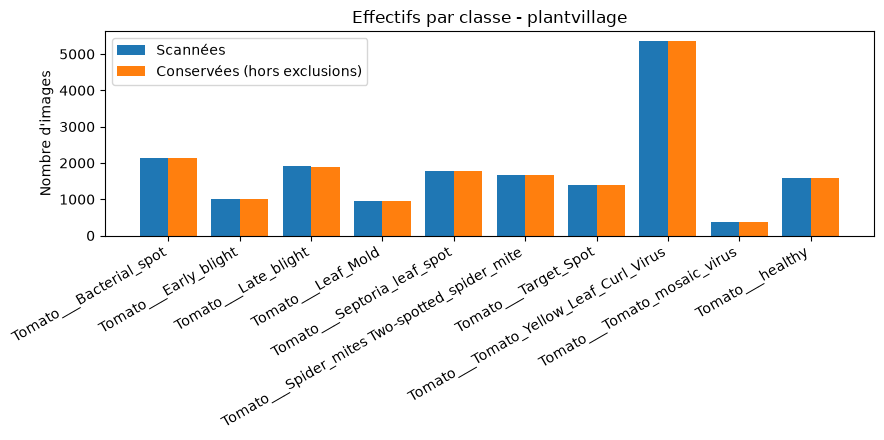

Figure 1 - Effectifs par classe avant et après exclusions (corpus plantvillage).


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(counts))
ax.bar(x - 0.2, counts["n_scannees"], 0.4, label="Scannées")
ax.bar(x + 0.2, counts["n_conservees"], 0.4, label="Conservées (hors exclusions)")
ax.set_xticks(x)
ax.set_xticklabels(counts["class_origin"], rotation=30, ha="right")
ax.set_ylabel("Nombre d'images")
ax.set_title(f"Effectifs par classe - {CORPUS}")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "fig_effectifs.png", dpi=150)
plt.show()
print(f"Figure 1 - Effectifs par classe avant et après exclusions (corpus {CORPUS}).")

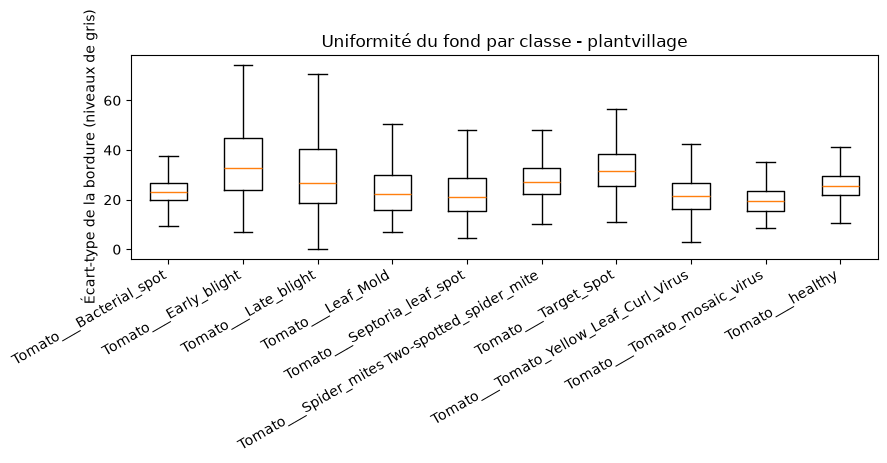

Figure 2 - Dispersion de border_std par classe : des valeurs basses indiquent un fond uniforme (risque d'apprentissage du fond). À comparer entre PlantVillage et PlantDoc.


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
classes = sorted(rd["class_origin"].unique())
ax.boxplot([rd.loc[rd["class_origin"] == c, "border_std"] for c in classes], showfliers=False)
ax.set_xticks(range(1, len(classes) + 1))
ax.set_xticklabels(classes, rotation=30, ha="right")
ax.set_ylabel("Écart-type de la bordure (niveaux de gris)")
ax.set_title(f"Uniformité du fond par classe - {CORPUS}")
plt.tight_layout()
plt.savefig(OUT / "fig_fond.png", dpi=150)
plt.show()
print("Figure 2 - Dispersion de border_std par classe : des valeurs basses indiquent un fond uniforme (risque d'apprentissage du fond). À comparer entre PlantVillage et PlantDoc.")

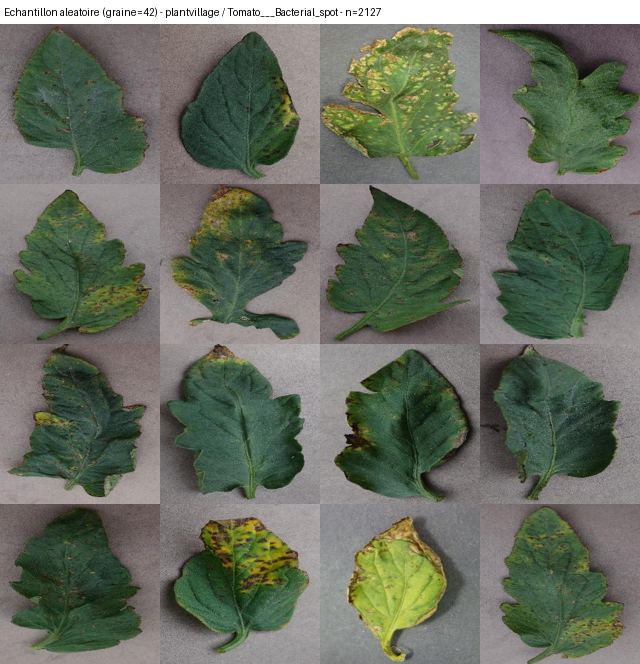

Figure - Planche de contrôle visuel, classe Tomato___Bacterial_spot : repérer annotations discutables et biais de fond.


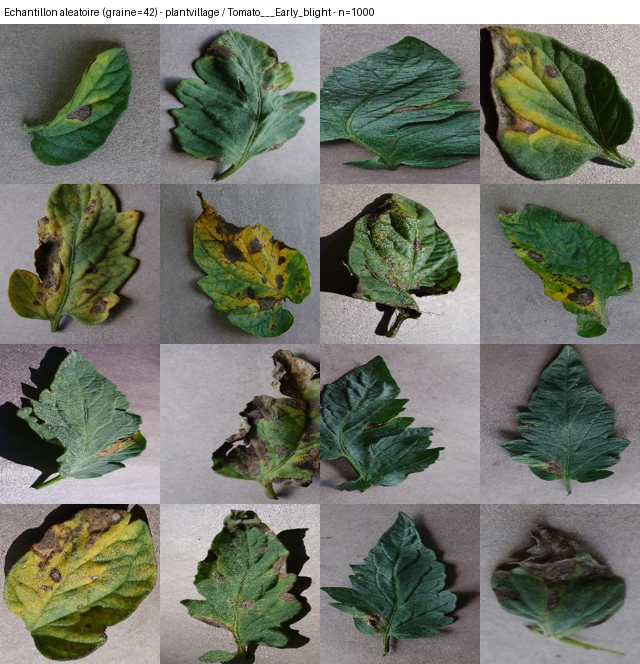

Figure - Planche de contrôle visuel, classe Tomato___Early_blight : repérer annotations discutables et biais de fond.


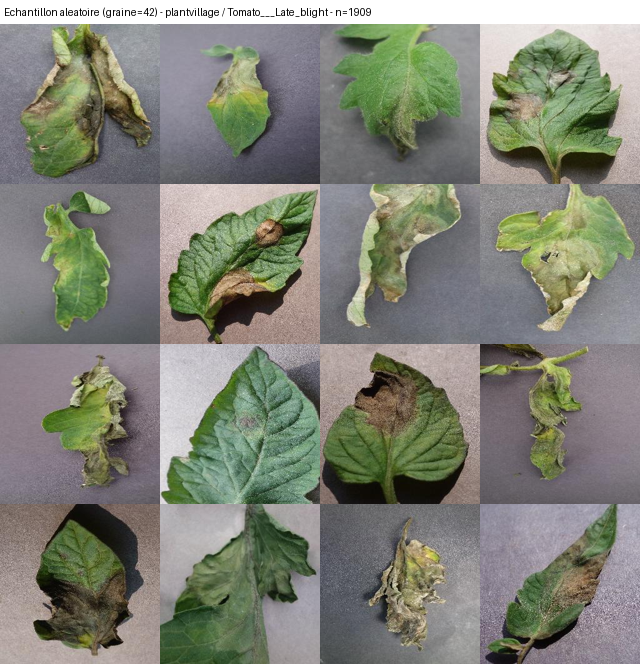

Figure - Planche de contrôle visuel, classe Tomato___Late_blight : repérer annotations discutables et biais de fond.


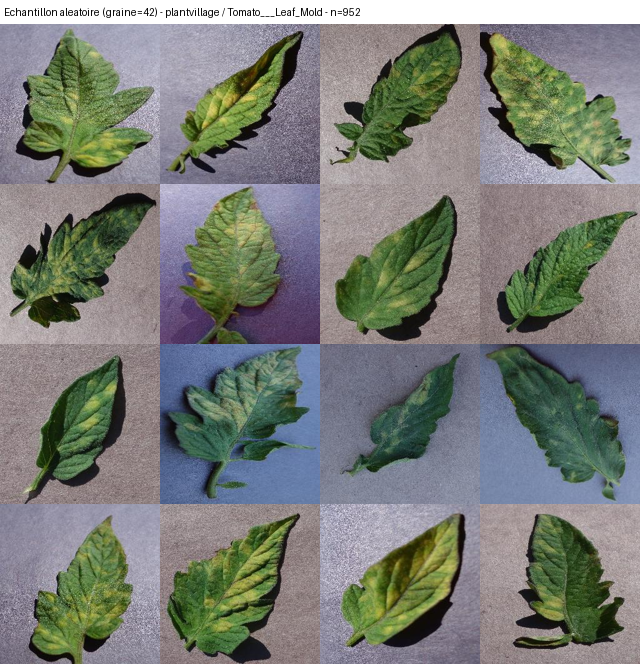

Figure - Planche de contrôle visuel, classe Tomato___Leaf_Mold : repérer annotations discutables et biais de fond.


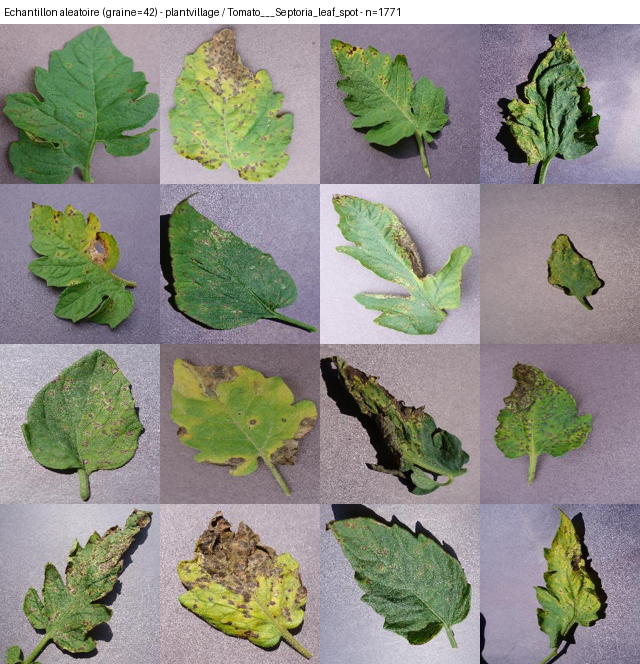

Figure - Planche de contrôle visuel, classe Tomato___Septoria_leaf_spot : repérer annotations discutables et biais de fond.


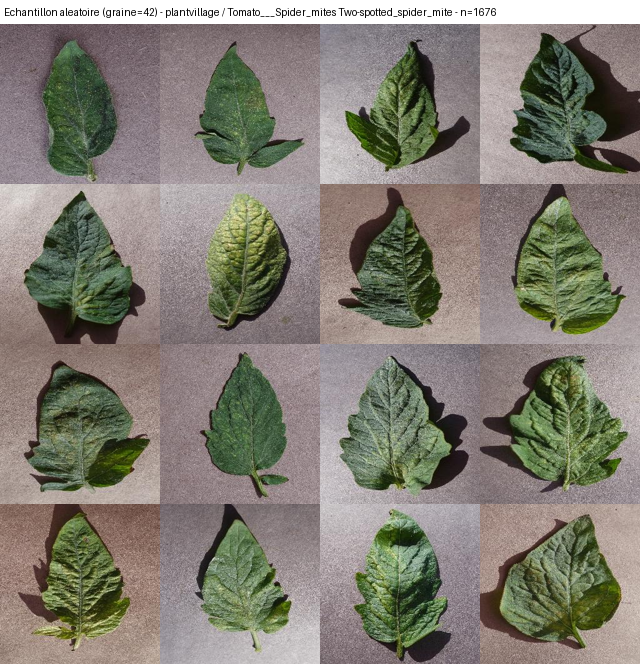

Figure - Planche de contrôle visuel, classe Tomato___Spider_mites Two-spotted_spider_mite : repérer annotations discutables et biais de fond.


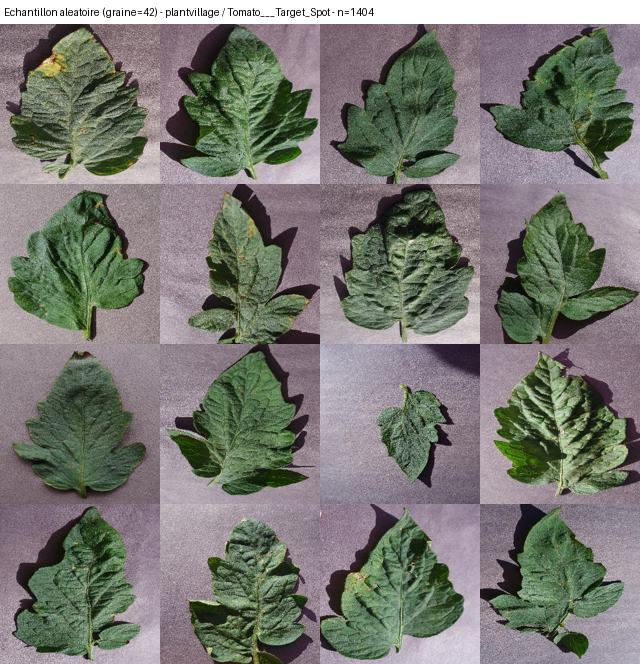

Figure - Planche de contrôle visuel, classe Tomato___Target_Spot : repérer annotations discutables et biais de fond.


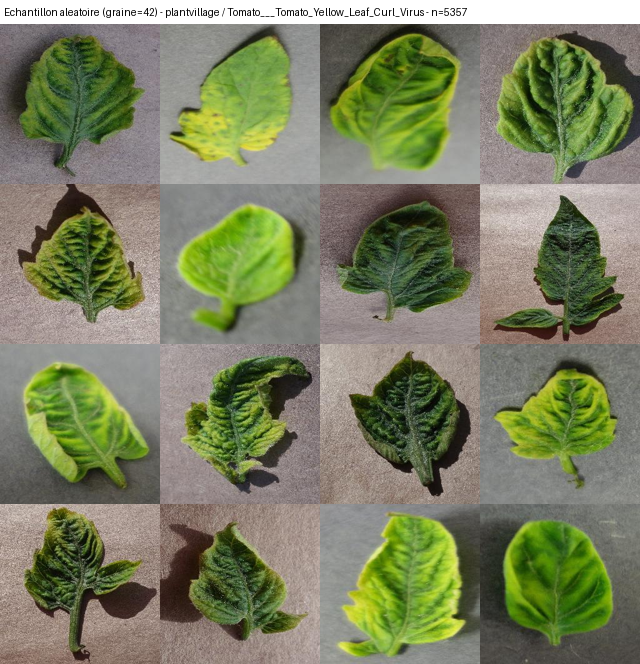

Figure - Planche de contrôle visuel, classe Tomato___Tomato_Yellow_Leaf_Curl_Virus : repérer annotations discutables et biais de fond.


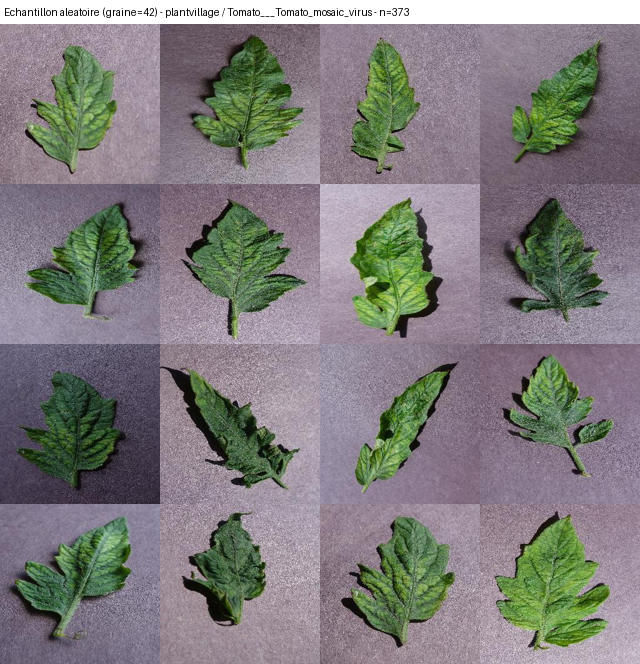

Figure - Planche de contrôle visuel, classe Tomato___Tomato_mosaic_virus : repérer annotations discutables et biais de fond.


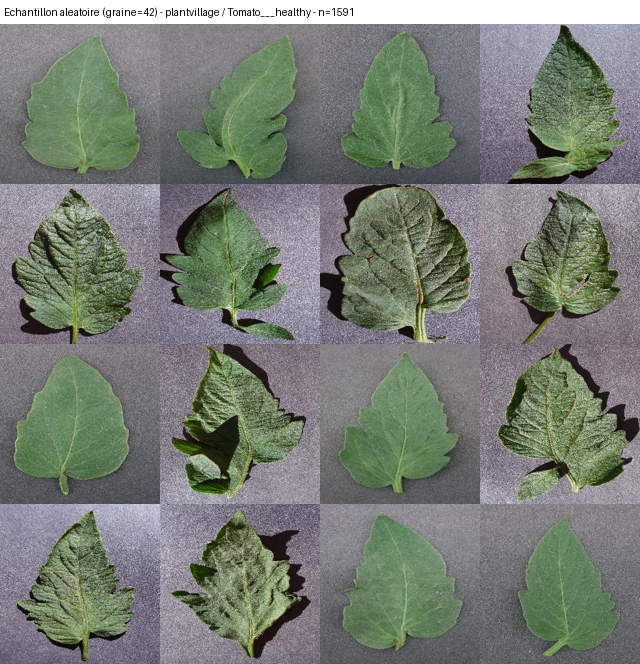

Figure - Planche de contrôle visuel, classe Tomato___healthy : repérer annotations discutables et biais de fond.


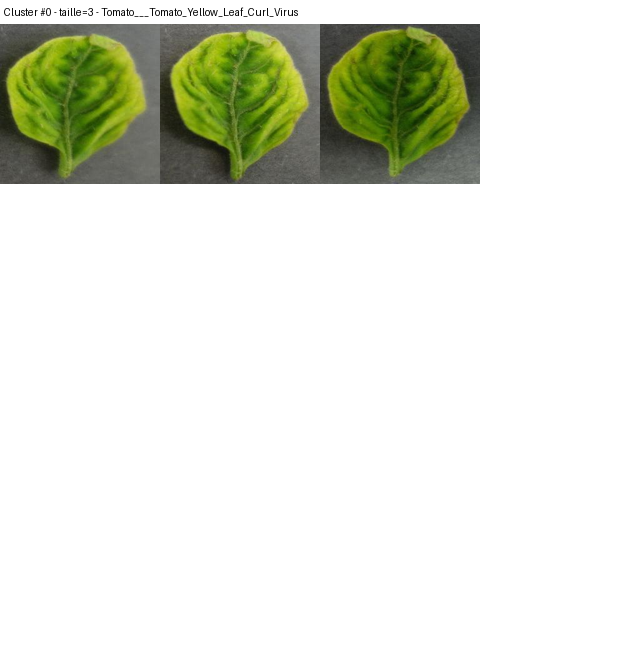

Figure - Cluster de quasi-doublons #0 : confirmer visuellement qu'il s'agit de la même feuille.


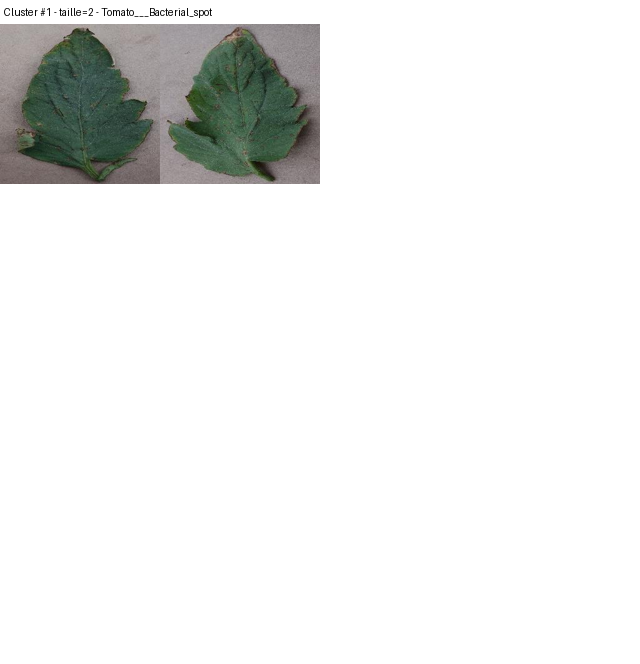

Figure - Cluster de quasi-doublons #1 : confirmer visuellement qu'il s'agit de la même feuille.


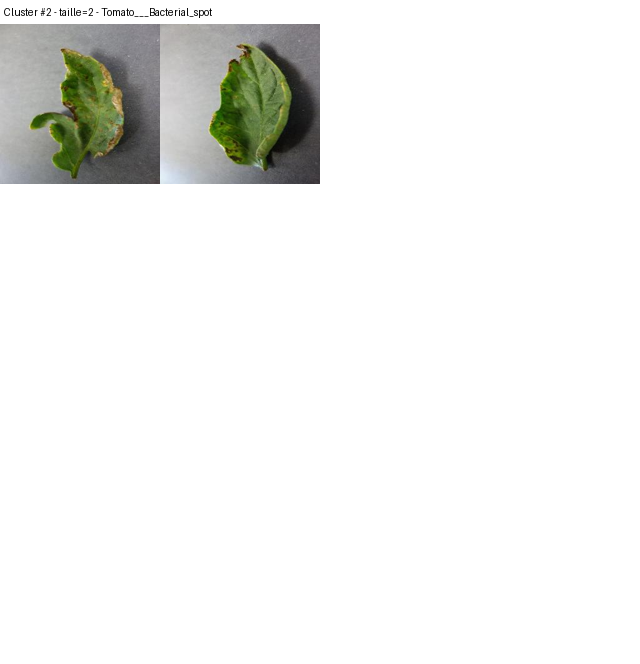

Figure - Cluster de quasi-doublons #2 : confirmer visuellement qu'il s'agit de la même feuille.


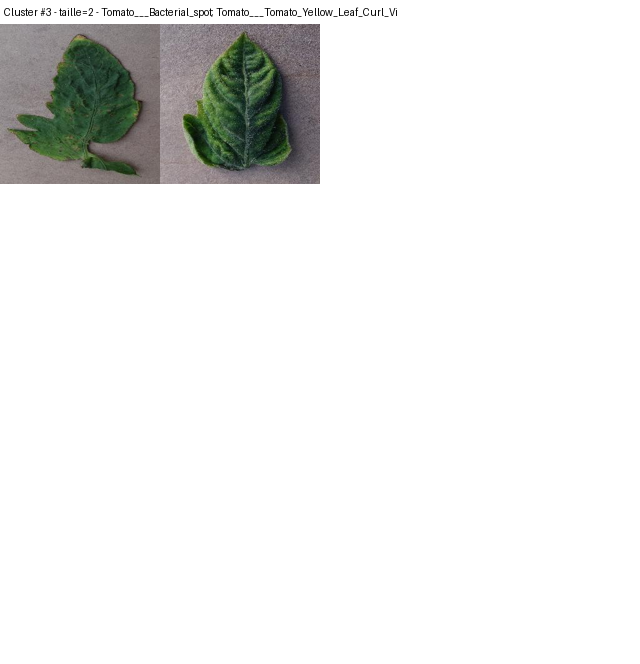

Figure - Cluster de quasi-doublons #3 : confirmer visuellement qu'il s'agit de la même feuille.


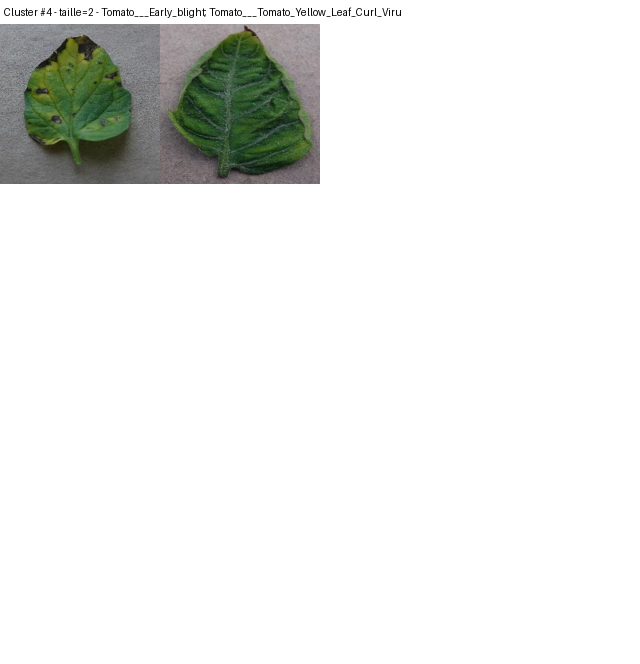

Figure - Cluster de quasi-doublons #4 : confirmer visuellement qu'il s'agit de la même feuille.


In [10]:
def contact_sheet(paths, title, cols=4, rows=4, tile=160, seed=SEED):
    rng = random.Random(seed)
    sample = rng.sample(sorted(paths), min(len(paths), cols * rows))
    header = 24
    sheet = Image.new("RGB", (cols * tile, rows * tile + header), "white")
    ImageDraw.Draw(sheet).text((4, 6), title, fill="black")
    for k, p in enumerate(sample):
        try:
            with Image.open(p) as im:
                im = im.convert("RGB")
                im.thumbnail((tile, tile))
                sheet.paste(im, ((k % cols) * tile + (tile - im.width) // 2,
                                 header + (k // cols) * tile + (tile - im.height) // 2))
        except Exception:
            continue
    return sheet


if SHEETS:
    (OUT / "review").mkdir(exist_ok=True)
    for c, g in rd.groupby("class_origin"):
        s = contact_sheet(g["path"].tolist(), f"Echantillon aleatoire (graine={SEED}) - {CORPUS} / {c} - n={len(g)}")
        s.save(OUT / "review" / f"sheet_{re.sub(r'[^A-Za-z0-9]+', '_', c)}.png")
        display(s)
        print(f"Figure - Planche de contrôle visuel, classe {c} : repérer annotations discutables et biais de fond.")
    for _, r in clusters.head(5).iterrows():
        g = df[df["near_dup_cluster"] == r["near_dup_cluster"]]
        s = contact_sheet(g["path"].tolist(), f"Cluster #{int(r['near_dup_cluster'])} - taille={int(r['taille'])} - {r['classes'][:60]}")
        s.save(OUT / "review" / f"cluster_{int(r['near_dup_cluster'])}.png")
        display(s)
        print(f"Figure - Cluster de quasi-doublons #{int(r['near_dup_cluster'])} : confirmer visuellement qu'il s'agit de la même feuille.")

## 8. Sauvegarde des livrables

Le manifeste, le journal d'exclusions, les tableaux, la configuration (versions, commit git, empreinte du manifeste) et le rapport Markdown sont écrits dans `OUT`.

In [11]:
def md_table(d: pd.DataFrame) -> str:
    d = d.copy()
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]):
            d[c] = d[c].round(2)
    head = "| " + " | ".join(map(str, d.columns)) + " |"
    sep = "|" + "|".join("---" for _ in d.columns) + "|"
    body = ["| " + " | ".join(str(v) for v in r) + " |" for r in d.itertuples(index=False)]
    return "\n".join([head, sep] + body)


def git_commit() -> str:
    try:
        return subprocess.check_output(["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL, text=True).strip()
    except Exception:
        return ""


cols = ["image_id", "corpus", "relpath", "class_origin", "class_retained", "class_status", "variant", "split_origin",
        "width", "height", "fmt", "mode", "size_bytes", "sha256", "dhash", "mean_lum", "contrast", "blur_lapvar",
        "border_std", "readable", "error", "keep", "exclusion_reason", "label_conflict", "near_dup_cluster",
        "cluster_multi_class", "in_scope", "kept_for_dataset"]
manifest_path = OUT / "manifest.csv"
df[cols].to_csv(manifest_path, index=False)
df.loc[~df["keep"], ["image_id", "class_origin", "exclusion_reason"]].to_csv(OUT / "exclusion_log.csv", index=False)
counts.to_csv(OUT / "class_counts.csv", index=False)
res_stats.to_csv(OUT / "resolution_stats.csv", index=False)
qual.to_csv(OUT / "quality_stats.csv", index=False)
clusters.to_csv(OUT / "near_dup_clusters.csv", index=False)

manifest_sha = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
config = {
    "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "parametres": {"corpus": CORPUS, "root": str(ROOT), "out": str(OUT), "all_crops": ALL_CROPS,
                   "min_side": MIN_SIDE, "dhash_threshold": DHASH_THRESHOLD, "seed": SEED},
    "corpus_revision": REVISION,
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "pillow": Image.__version__},
    "platform": platform.platform(),
    "git_commit": git_commit(),
    "n_images_scannees": int(len(df)),
    "manifest_sha256": manifest_sha,
}
(OUT / "audit_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

to_check = mapping[mapping["status"] != "CONFIRME"][["class_origin", "class_retained", "status"]]
n_keep = int(df["kept_for_dataset"].sum())
report = f"""# Rapport d'audit - {CORPUS}

*Généré le {config['date_utc']} UTC - révision du corpus : {REVISION or 'non renseignée'} - empreinte du manifeste : `{manifest_sha[:16]}...`*

## Synthèse
- Images inventoriées : **{len(df)}** ; illisibles : **{int((~df['readable']).sum())}** ; exclues : **{int((~df['keep']).sum())}** ; conservées dans le périmètre : **{n_keep}**.
- Groupes de quasi-doublons à examiner : **{len(clusters)}**.

## Effectifs par classe
{md_table(counts)}

*Tableau 1 - Effectifs avant et après nettoyage.*

## Motifs d'exclusion
{md_table(reasons) if len(reasons) else 'Aucune exclusion.'}

*Tableau 2 - Exclusions par motif.*

## Résolutions et formats
{md_table(res_stats)}

*Tableau 3 - Dimensions et formats par classe.*

## Qualité et uniformité du fond
{md_table(qual)}

*Tableau 4 - Médianes par classe (luminance, contraste, flou, border_std).*

## Correspondances à valider
{md_table(to_check)}

*Tableau 5 - Classes dont le statut n'est pas encore CONFIRME.*
"""
(OUT / "audit_report.md").write_text(report, encoding="utf-8")
print(f"Audit terminé : {n_keep} images conservées / {len(df)}. Livrables dans {OUT.resolve()}")

Audit terminé : 7209 images conservées / 18160. Livrables dans C:\Users\ayman\Desktop\PFA\Code Source\audit\pv
